# Notebook 08 _ Validation externe de la méthodologie de prévision H+1

## Objectif

L'objectif de ce notebook est d'évaluer la **transférabilité de la méthodologie**
développée dans le projet principal sur un jeu de données énergétique externe
et indépendant.

Le cas étudié ici concerne **l'Allemagne**, à partir des données
Open Power System Data (OPSD), issues principalement de la plateforme
ENTSO-E Transparency.

Contrairement au dataset principal du projet, qui est disponible à une
résolution de 5 minutes, les données utilisées ici sont disponibles à une
résolution **horaire**.

La méthodologie reste cependant identique dans son principe :

1. sélectionner les séries énergétiques et météorologiques pertinentes ;
2. construire une cible de prévision à **H+1 heure** ;
3. créer uniquement des caractéristiques disponibles au moment de la prédiction ;
4. effectuer un découpage chronologique des données ;
5. comparer une régression linéaire et HistGradientBoosting ;
6. comparer les modèles à une baseline naïve ;
7. évaluer les performances avec MAE, RMSE et R².

Cette expérimentation ne vise pas à réutiliser directement les modèles `.pkl`
du projet principal, car les variables disponibles dans ce dataset externe
sont différentes.

Elle vise à tester la **robustesse et la transférabilité de la démarche
méthodologique**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# CHEMINS DU PROJET

NOTEBOOK_DIR = Path.cwd()

# Si le notebook est exécuté depuis /notebooks
if NOTEBOOK_DIR.name == "notebooks":
    PROJECT_DIR = NOTEBOOK_DIR.parent
else:
    PROJECT_DIR = NOTEBOOK_DIR


# DOSSIERS

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# FICHIERS SOURCES

ELECTRICITY_FILE = (
    RAW_DIR / "time_series_60min_singleindex.csv"
)

WEATHER_FILE = (
    RAW_DIR / "weather_data.csv"
)


# CONTRÔLE DES CHEMINS

print("CONFIGURATION DU PROJET")

print("Projet      :", PROJECT_DIR)
print("Raw         :", RAW_DIR)
print("Processed   :", PROCESSED_DIR)
print("Results     :", RESULTS_DIR)
print("Figures     :", FIGURES_DIR)

print("\nFichiers sources :")
print("Électricité :", ELECTRICITY_FILE)
print("Météo       :", WEATHER_FILE)

print("\nExistence des fichiers :")
print("Électricité :", ELECTRICITY_FILE.exists())
print("Météo       :", WEATHER_FILE.exists())



CONFIGURATION DU PROJET
Projet      : c:\Users\celes\Desktop\PFE
Raw         : c:\Users\celes\Desktop\PFE\data\raw
Processed   : c:\Users\celes\Desktop\PFE\data\processed
Results     : c:\Users\celes\Desktop\PFE\results
Figures     : c:\Users\celes\Desktop\PFE\figures

Fichiers sources :
Électricité : c:\Users\celes\Desktop\PFE\data\raw\time_series_60min_singleindex.csv
Météo       : c:\Users\celes\Desktop\PFE\data\raw\weather_data.csv

Existence des fichiers :
Électricité : True
Météo       : True


## 1. Sélection des données allemandes

Le fichier OPSD contient des séries énergétiques pour plusieurs pays européens.

Pour la validation externe, seules les séries nationales allemandes suivantes
sont conservées :

- `DE_load_actual_entsoe_transparency` :
  demande électrique réelle en MW ;
- `DE_solar_generation_actual` :
  production solaire réelle en MW ;
- `DE_wind_generation_actual` :
  production éolienne réelle en MW.

Les données météorologiques sont extraites du second fichier OPSD à partir
des séries allemandes :

- température ;
- rayonnement solaire direct horizontal ;
- rayonnement solaire diffus horizontal.

L'utilisation de variables appartenant au même pays évite de mélanger des
contextes géographiques différents.

In [2]:
# CHARGEMENT DES DONNÉES BRUTES

electricity_raw = pd.read_csv(
    ELECTRICITY_FILE,
    low_memory=False
)

weather_raw = pd.read_csv(
    WEATHER_FILE,
    low_memory=False
)

print("DONNÉES ÉLECTRIQUES")

print("Dimensions :", electricity_raw.shape)

print("\nPremières colonnes :")
print(
    electricity_raw.columns[:20].tolist()
)

print("DONNÉES MÉTÉOROLOGIQUES")

print("Dimensions :", weather_raw.shape)

print("\nPremières colonnes :")
print(
    weather_raw.columns[:20].tolist()
)

DONNÉES ÉLECTRIQUES
Dimensions : (50401, 300)

Premières colonnes :
['utc_timestamp', 'cet_cest_timestamp', 'AT_load_actual_entsoe_transparency', 'AT_load_forecast_entsoe_transparency', 'AT_price_day_ahead', 'AT_solar_generation_actual', 'AT_wind_onshore_generation_actual', 'BE_load_actual_entsoe_transparency', 'BE_load_forecast_entsoe_transparency', 'BE_solar_generation_actual', 'BE_wind_generation_actual', 'BE_wind_offshore_generation_actual', 'BE_wind_onshore_generation_actual', 'BG_load_actual_entsoe_transparency', 'BG_load_forecast_entsoe_transparency', 'BG_solar_generation_actual', 'BG_wind_onshore_generation_actual', 'CH_load_actual_entsoe_transparency', 'CH_load_forecast_entsoe_transparency', 'CH_solar_capacity']
DONNÉES MÉTÉOROLOGIQUES
Dimensions : (350640, 85)

Premières colonnes :
['utc_timestamp', 'AT_temperature', 'AT_radiation_direct_horizontal', 'AT_radiation_diffuse_horizontal', 'BE_temperature', 'BE_radiation_direct_horizontal', 'BE_radiation_diffuse_horizontal', 'BG_t

In [3]:
# RECHERCHE DES COLONNES ALLEMANDES

germany_electricity_columns = [
    column
    for column in electricity_raw.columns
    if column.startswith("DE_")
    and (
        "load_actual" in column
        or "solar_generation_actual" in column
        or "wind_generation_actual" in column
    )
]

germany_weather_columns = [
    column
    for column in weather_raw.columns
    if column.startswith("DE_")
]

print("COLONNES ÉNERGÉTIQUES ALLEMANDES PERTINENTES")

for column in germany_electricity_columns:
    print(column)

print("COLONNES MÉTÉOROLOGIQUES ALLEMANDES")

for column in germany_weather_columns:
    print(column)

COLONNES ÉNERGÉTIQUES ALLEMANDES PERTINENTES
DE_load_actual_entsoe_transparency
DE_solar_generation_actual
DE_wind_generation_actual
DE_50hertz_load_actual_entsoe_transparency
DE_50hertz_solar_generation_actual
DE_50hertz_wind_generation_actual
DE_LU_load_actual_entsoe_transparency
DE_LU_solar_generation_actual
DE_LU_wind_generation_actual
DE_amprion_load_actual_entsoe_transparency
DE_amprion_solar_generation_actual
DE_tennet_load_actual_entsoe_transparency
DE_tennet_solar_generation_actual
DE_tennet_wind_generation_actual
DE_transnetbw_load_actual_entsoe_transparency
DE_transnetbw_solar_generation_actual
COLONNES MÉTÉOROLOGIQUES ALLEMANDES
DE_temperature
DE_radiation_direct_horizontal
DE_radiation_diffuse_horizontal


## 2. Construction du jeu de données externe allemand

Les séries nationales allemandes sont extraites des deux sources OPSD.

Les données énergétiques comprennent la demande électrique ainsi que les
productions solaire et éolienne réellement enregistrées. Elles sont complétées
par trois variables météorologiques allemandes : température, rayonnement
direct horizontal et rayonnement diffus horizontal.

Les deux sources sont synchronisées à partir de leur horodatage UTC.

À cette étape, aucune interpolation ni suppression arbitraire n'est effectuée.
La qualité des données et les valeurs manquantes seront d'abord analysées
après la fusion.

In [4]:
# EXTRACTION DES VARIABLES UTILES

electricity_de = electricity_raw[
    [
        "utc_timestamp",
        "DE_load_actual_entsoe_transparency",
        "DE_solar_generation_actual",
        "DE_wind_generation_actual",
    ]
].copy()

weather_de = weather_raw[
    [
        "utc_timestamp",
        "DE_temperature",
        "DE_radiation_direct_horizontal",
        "DE_radiation_diffuse_horizontal",
    ]
].copy()


# Noms plus simples pour la suite du notebook
electricity_de = electricity_de.rename(
    columns={
        "DE_load_actual_entsoe_transparency": "Demand",
        "DE_solar_generation_actual": "PV",
        "DE_wind_generation_actual": "Wind",
    }
)

weather_de = weather_de.rename(
    columns={
        "DE_temperature": "Temperature",
        "DE_radiation_direct_horizontal": "Radiation_direct",
        "DE_radiation_diffuse_horizontal": "Radiation_diffuse",
    }
)


print("Électricité :", electricity_de.shape)
print("Météo       :", weather_de.shape)

display(electricity_de.head())
display(weather_de.head())

Électricité : (50401, 4)
Météo       : (350640, 4)


,utc_timestamp,Demand,PV,Wind
0,2014-12-31T23:00:00Z,NaN,NaN,NaN
1,2015-01-01T00:00:00Z,41151.0,NaN,8852.0
2,2015-01-01T01:00:00Z,40135.0,NaN,9054.0
3,2015-01-01T02:00:00Z,39106.0,NaN,9070.0
4,2015-01-01T03:00:00Z,38765.0,NaN,9163.0


,utc_timestamp,Temperature,Radiation_direct,Radiation_diffuse
0,1980-01-01T00:00:00Z,-1.261,0.0,0.0
1,1980-01-01T01:00:00Z,-1.414,0.0,0.0
2,1980-01-01T02:00:00Z,-1.571,0.0,0.0
3,1980-01-01T03:00:00Z,-1.760,0.0,0.0
4,1980-01-01T04:00:00Z,-1.995,0.0,0.0


In [5]:
# CONVERSION DES TIMESTAMPS

electricity_de["utc_timestamp"] = pd.to_datetime(
    electricity_de["utc_timestamp"],
    utc=True,
    errors="coerce",
)

weather_de["utc_timestamp"] = pd.to_datetime(
    weather_de["utc_timestamp"],
    utc=True,
    errors="coerce",
)


print("PÉRIODES DISPONIBLES")

print(
    "Électricité :",
    electricity_de["utc_timestamp"].min(),
    "->",
    electricity_de["utc_timestamp"].max(),
)

print(
    "Météo       :",
    weather_de["utc_timestamp"].min(),
    "->",
    weather_de["utc_timestamp"].max(),
)

print("\nTimestamps invalides :")
print(
    "Électricité :",
    electricity_de["utc_timestamp"].isna().sum(),
)
print(
    "Météo       :",
    weather_de["utc_timestamp"].isna().sum(),
)

print("\nDoublons temporels :")
print(
    "Électricité :",
    electricity_de["utc_timestamp"].duplicated().sum(),
)
print(
    "Météo       :",
    weather_de["utc_timestamp"].duplicated().sum(),
)

PÉRIODES DISPONIBLES
Électricité : 2014-12-31 23:00:00+00:00 -> 2020-09-30 23:00:00+00:00
Météo       : 1980-01-01 00:00:00+00:00 -> 2019-12-31 23:00:00+00:00

Timestamps invalides :
Électricité : 0
Météo       : 0

Doublons temporels :
Électricité : 0
Météo       : 0


In [6]:
# FUSION ÉNERGIE + MÉTÉO

germany = pd.merge(
    electricity_de,
    weather_de,
    on="utc_timestamp",
    how="inner",
    validate="one_to_one",
)

germany = (
    germany
    .sort_values("utc_timestamp")
    .reset_index(drop=True)
)

print("DATASET ALLEMAND APRÈS FUSION")

print("Dimensions :", germany.shape)

print(
    "Période :",
    germany["utc_timestamp"].min(),
    "->",
    germany["utc_timestamp"].max(),
)

print("\nValeurs manquantes :")
print(germany.isna().sum())

display(germany.head())

DATASET ALLEMAND APRÈS FUSION
Dimensions : (43825, 7)
Période : 2014-12-31 23:00:00+00:00 -> 2019-12-31 23:00:00+00:00

Valeurs manquantes :
utc_timestamp          0
Demand                 1
PV                   104
Wind                  75
Temperature            0
Radiation_direct       0
Radiation_diffuse      0
dtype: int64


,utc_timestamp,Demand,PV,Wind,Temperature,Radiation_direct,Radiation_diffuse
0,2014-12-31 23:00:00+00:00,NaN,NaN,NaN,-0.940,0.0,0.0
1,2015-01-01 00:00:00+00:00,41151.0,NaN,8852.0,-0.981,0.0,0.0
2,2015-01-01 01:00:00+00:00,40135.0,NaN,9054.0,-1.035,0.0,0.0
3,2015-01-01 02:00:00+00:00,39106.0,NaN,9070.0,-1.109,0.0,0.0
4,2015-01-01 03:00:00+00:00,38765.0,NaN,9163.0,-1.166,0.0,0.0


In [7]:
# CONTRÔLE DE LA FRÉQUENCE TEMPORELLE

time_diff = germany["utc_timestamp"].diff()

print("Intervalles les plus fréquents :")
print(time_diff.value_counts().head(10))

expected_frequency = pd.Timedelta(hours=1)

irregular_intervals = (
    time_diff.dropna() != expected_frequency
).sum()

print(
    "\nNombre d'intervalles différents de 1 heure :",
    irregular_intervals,
)

print(
    "Nombre total d'intervalles :",
    time_diff.notna().sum(),
)

Intervalles les plus fréquents :
utc_timestamp
0 days 01:00:00    43824
Name: count, dtype: int64

Nombre d'intervalles différents de 1 heure : 0
Nombre total d'intervalles : 43824


## 3. Contrôle qualité et préparation de la prévision H+1

La fusion produit une série temporelle continue à résolution horaire, sans
doublons ni irrégularités temporelles.

Quelques valeurs manquantes subsistent dans les séries énergétiques, tandis
que les variables météorologiques sont complètes.

Compte tenu de leur très faible proportion, les observations énergétiques
incomplètes sont supprimées plutôt qu'interpolées. Ce choix évite
d'introduire des valeurs artificielles dans les variables que le système
cherche précisément à prévoir.

La construction des cibles H+1 tient également compte de l'horodatage :
une cible n'est conservée que si l'observation suivante correspond
exactement à une heure après l'instant de référence.

In [8]:
# QUALITÉ DES DONNÉES

energy_columns = ["Demand", "PV", "Wind"]

missing_summary = pd.DataFrame({
    "Valeurs_manquantes": germany[energy_columns].isna().sum(),
    "Pourcentage": germany[energy_columns].isna().mean() * 100,
})

display(missing_summary.round(4))

germany_clean = (
    germany
    .dropna(subset=energy_columns)
    .copy()
    .reset_index(drop=True)
)

print("Observations avant nettoyage :", len(germany))
print("Observations après nettoyage :", len(germany_clean))
print("Observations supprimées       :", len(germany) - len(germany_clean))

print("\nValeurs manquantes restantes :")
print(germany_clean.isna().sum())

,Valeurs_manquantes,Pourcentage
Demand,1,0.0023
PV,104,0.2373
Wind,75,0.1711


Observations avant nettoyage : 43825
Observations après nettoyage : 43719
Observations supprimées       : 106

Valeurs manquantes restantes :
utc_timestamp        0
Demand               0
PV                   0
Wind                 0
Temperature          0
Radiation_direct     0
Radiation_diffuse    0
dtype: int64


In [9]:
# CONSTRUCTION DES CIBLES À H+1

germany_h1 = germany_clean.copy()

# Valeurs observées à la ligne suivante
germany_h1["Demand_H1"] = germany_h1["Demand"].shift(-1)
germany_h1["PV_H1"] = germany_h1["PV"].shift(-1)
germany_h1["Wind_H1"] = germany_h1["Wind"].shift(-1)

# Timestamp de cette observation future
germany_h1["timestamp_H1"] = (
    germany_h1["utc_timestamp"].shift(-1)
)

# Une ligne n'est valide que si la ligne suivante est
# exactement située une heure plus tard.
valid_h1 = (
    germany_h1["timestamp_H1"]
    - germany_h1["utc_timestamp"]
    == pd.Timedelta(hours=1)
)

print("Observations disponibles :", len(germany_h1))
print("Couples t -> t+1 valides  :", valid_h1.sum())
print("Couples rejetés          :", (~valid_h1).sum())

germany_h1 = (
    germany_h1.loc[valid_h1]
    .drop(columns="timestamp_H1")
    .reset_index(drop=True)
)

print("\nDataset H+1 final :", germany_h1.shape)

Observations disponibles : 43719
Couples t -> t+1 valides  : 43713
Couples rejetés          : 6

Dataset H+1 final : (43713, 10)


In [10]:
# VARIABLES TEMPORELLES

germany_h1["Hour"] = germany_h1["utc_timestamp"].dt.hour
germany_h1["DayOfWeek"] = germany_h1["utc_timestamp"].dt.dayofweek
germany_h1["Month"] = germany_h1["utc_timestamp"].dt.month

# Encodage cyclique
germany_h1["Hour_sin"] = np.sin(
    2 * np.pi * germany_h1["Hour"] / 24
)
germany_h1["Hour_cos"] = np.cos(
    2 * np.pi * germany_h1["Hour"] / 24
)

germany_h1["DayOfWeek_sin"] = np.sin(
    2 * np.pi * germany_h1["DayOfWeek"] / 7
)
germany_h1["DayOfWeek_cos"] = np.cos(
    2 * np.pi * germany_h1["DayOfWeek"] / 7
)

germany_h1["Month_sin"] = np.sin(
    2 * np.pi * (germany_h1["Month"] - 1) / 12
)
germany_h1["Month_cos"] = np.cos(
    2 * np.pi * (germany_h1["Month"] - 1) / 12
)

display(germany_h1.head())

,utc_timestamp,Demand,PV,Wind,Temperature,Radiation_direct,Radiation_diffuse,Demand_H1,PV_H1,Wind_H1,Hour,DayOfWeek,Month,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,Month_sin,Month_cos
0,2015-01-01 07:00:00+00:00,41133.0,71.0,10208.0,-1.692,0.4328,6.7680,42963.0,773.0,10029.0,7,3,1,0.965926,-0.258819,0.433884,-0.900969,0.0,1.0
1,2015-01-01 08:00:00+00:00,42963.0,773.0,10029.0,-1.046,8.8773,51.9464,45088.0,2117.0,10550.0,8,3,1,0.866025,-0.500000,0.433884,-0.900969,0.0,1.0
2,2015-01-01 09:00:00+00:00,45088.0,2117.0,10550.0,0.072,34.1583,97.0929,47013.0,3364.0,11390.0,9,3,1,0.707107,-0.707107,0.433884,-0.900969,0.0,1.0
3,2015-01-01 10:00:00+00:00,47013.0,3364.0,11390.0,0.866,56.5458,120.2907,48159.0,4198.0,12103.0,10,3,1,0.500000,-0.866025,0.433884,-0.900969,0.0,1.0
4,2015-01-01 11:00:00+00:00,48159.0,4198.0,12103.0,1.493,62.8690,126.2112,47164.0,3500.0,12505.0,11,3,1,0.258819,-0.965926,0.433884,-0.900969,0.0,1.0


## 4. Variables explicatives et découpage chronologique

Pour chaque cible, la valeur observée à l'instant `t` est utilisée pour prévoir
sa valeur à `t+1 heure`.

Les variables météorologiques disponibles à l'instant de référence ainsi que
des variables calendaires cycliques sont également utilisées.

Trois problèmes de régression sont étudiés séparément :

- production photovoltaïque à H+1 ;
- production éolienne à H+1 ;
- demande électrique à H+1.

Le découpage des données est strictement chronologique afin de respecter la
nature temporelle du problème :

- **70 %** pour l'entraînement ;
- **15 %** pour la validation ;
- **15 %** pour le test final externe.

Aucun mélange aléatoire des observations n'est effectué.

Le jeu de validation sert à comparer les approches tandis que le dernier bloc
temporel est conservé pour l'évaluation finale.

In [11]:
# VARIABLES EXPLICATIVES PAR CIBLE

calendar_features = [
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "Month_sin",
    "Month_cos",
]

feature_sets = {
    "Production photovoltaïque": [
        "PV",
        "Temperature",
        "Radiation_direct",
        "Radiation_diffuse",
        *calendar_features,
    ],

    "Production éolienne": [
        "Wind",
        "Temperature",
        *calendar_features,
    ],

    "Demande électrique": [
        "Demand",
        "Temperature",
        *calendar_features,
    ],
}

targets = {
    "Production photovoltaïque": "PV_H1",
    "Production éolienne": "Wind_H1",
    "Demande électrique": "Demand_H1",
}

for target_name in targets:
    print(target_name)
    print("Cible :", targets[target_name])
    print("Features :", feature_sets[target_name])

Production photovoltaïque
Cible : PV_H1
Features : ['PV', 'Temperature', 'Radiation_direct', 'Radiation_diffuse', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Month_sin', 'Month_cos']
Production éolienne
Cible : Wind_H1
Features : ['Wind', 'Temperature', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Month_sin', 'Month_cos']
Demande électrique
Cible : Demand_H1
Features : ['Demand', 'Temperature', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Month_sin', 'Month_cos']


In [12]:
# DÉCOUPAGE CHRONOLOGIQUE

n = len(germany_h1)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_df = germany_h1.iloc[:train_end].copy()
validation_df = germany_h1.iloc[train_end:validation_end].copy()
test_df = germany_h1.iloc[validation_end:].copy()

print("DÉCOUPAGE CHRONOLOGIQUE")

print(f"Total      : {len(germany_h1):,}")
print(f"Train      : {len(train_df):,}")
print(f"Validation : {len(validation_df):,}")
print(f"Test       : {len(test_df):,}")

print("\nPériodes :")

print(
    "Train      :",
    train_df["utc_timestamp"].min(),
    "->",
    train_df["utc_timestamp"].max(),
)

print(
    "Validation :",
    validation_df["utc_timestamp"].min(),
    "->",
    validation_df["utc_timestamp"].max(),
)

print(
    "Test       :",
    test_df["utc_timestamp"].min(),
    "->",
    test_df["utc_timestamp"].max(),
)

# Contrôle anti-fuite
assert (
    train_df["utc_timestamp"].max()
    < validation_df["utc_timestamp"].min()
)

assert (
    validation_df["utc_timestamp"].max()
    < test_df["utc_timestamp"].min()
)

print("\nContrôle chronologique : OK")

DÉCOUPAGE CHRONOLOGIQUE
Total      : 43,713
Train      : 30,599
Validation : 6,557
Test       : 6,557

Périodes :
Train      : 2015-01-01 07:00:00+00:00 -> 2018-07-03 12:00:00+00:00
Validation : 2018-07-03 13:00:00+00:00 -> 2019-04-02 17:00:00+00:00
Test       : 2019-04-02 18:00:00+00:00 -> 2019-12-31 22:00:00+00:00

Contrôle chronologique : OK


## 5. Baseline naïve H+1

Une prévision naïve est utilisée comme référence.

Pour chaque cible, la baseline suppose que la valeur observée à `t+1 heure`
sera identique à celle observée à l'instant `t`.

Cette référence est particulièrement exigeante pour un horizon court comme
H+1, car les séries énergétiques présentent généralement une forte
autocorrélation temporelle.

Un modèle de Machine Learning n'est donc réellement intéressant que s'il
apporte une amélioration mesurable par rapport à cette stratégie simple.

In [13]:
# FONCTION D'ÉVALUATION

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred),
    }


# BASELINE NAÏVE SUR LA VALIDATION

baseline_current_columns = {
    "Production photovoltaïque": "PV",
    "Production éolienne": "Wind",
    "Demande électrique": "Demand",
}

baseline_results = []

for target_name, target_column in targets.items():

    y_true = validation_df[target_column]

    current_column = baseline_current_columns[target_name]

    y_pred = validation_df[current_column]

    metrics = regression_metrics(y_true, y_pred)

    baseline_results.append({
        "Cible": target_name,
        "Modèle": "Baseline naïve",
        **metrics,
    })


baseline_results_df = pd.DataFrame(baseline_results)

display(
    baseline_results_df.round(3)
)

,Cible,Modèle,MAE,RMSE,R2
0,Production photovoltaïque,Baseline naïve,1120.438,1995.342,0.907
1,Production éolienne,Baseline naïve,738.891,1008.357,0.991
2,Demande électrique,Baseline naïve,1959.238,2591.287,0.930


## 6. Comparaison des modèles sur le jeu de validation

Deux familles de modèles sont évaluées afin de conserver une méthodologie
comparable à celle du projet principal :

- **Régression linéaire**, utilisée comme modèle simple et interprétable ;
- **HistGradientBoostingRegressor**, capable de modéliser des relations
  non linéaires entre les variables.

Les modèles sont entraînés exclusivement sur le bloc d'entraînement puis
évalués sur le bloc de validation.

La baseline naïve H+1 reste la référence principale : compte tenu de la forte
persistance des séries énergétiques à court terme, un modèle complexe n'est
pertinent que s'il améliore cette référence.

Le jeu de test externe reste totalement isolé pendant cette étape.

In [14]:
# ENTRAÎNEMENT ET ÉVALUATION SUR LA VALIDATION

validation_results = []
trained_models = {}

for target_name, target_column in targets.items():

    print(target_name.upper())

    features = feature_sets[target_name]

    X_train = train_df[features]
    y_train = train_df[target_column]

    X_val = validation_df[features]
    y_val = validation_df[target_column]

    # 1. RÉGRESSION LINÉAIRE

    linear_model = LinearRegression()

    linear_model.fit(
        X_train,
        y_train
    )

    linear_pred = linear_model.predict(X_val)

    linear_metrics = regression_metrics(
        y_val,
        linear_pred
    )

    validation_results.append({
        "Cible": target_name,
        "Modèle": "Régression linéaire",
        **linear_metrics,
    })

    # 2. HISTGRADIENTBOOSTING

    boosting_model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42,
    )

    boosting_model.fit(
        X_train,
        y_train
    )

    boosting_pred = boosting_model.predict(X_val)

    boosting_metrics = regression_metrics(
        y_val,
        boosting_pred
    )

    validation_results.append({
        "Cible": target_name,
        "Modèle": "HistGradientBoosting",
        **boosting_metrics,
    })

    # Conservation temporaire
    trained_models[target_name] = {
        "Régression linéaire": linear_model,
        "HistGradientBoosting": boosting_model,
    }

    print("Régression linéaire")
    print(
        f"MAE={linear_metrics['MAE']:.2f} | "
        f"RMSE={linear_metrics['RMSE']:.2f} | "
        f"R²={linear_metrics['R2']:.4f}"
    )

    print("\nHistGradientBoosting")
    print(
        f"MAE={boosting_metrics['MAE']:.2f} | "
        f"RMSE={boosting_metrics['RMSE']:.2f} | "
        f"R²={boosting_metrics['R2']:.4f}"
    )

PRODUCTION PHOTOVOLTAÏQUE
Régression linéaire
MAE=1236.53 | RMSE=1572.30 | R²=0.9420

HistGradientBoosting
MAE=184.53 | RMSE=353.93 | R²=0.9971
PRODUCTION ÉOLIENNE
Régression linéaire
MAE=730.71 | RMSE=998.92 | R²=0.9913

HistGradientBoosting
MAE=795.55 | RMSE=1156.47 | R²=0.9883
DEMANDE ÉLECTRIQUE
Régression linéaire
MAE=1452.31 | RMSE=1955.33 | R²=0.9604

HistGradientBoosting
MAE=457.65 | RMSE=627.16 | R²=0.9959


In [15]:
# COMPARAISON BASELINE + MODÈLES ML

validation_results_df = pd.DataFrame(
    validation_results
)

comparison_validation = pd.concat(
    [
        baseline_results_df,
        validation_results_df,
    ],
    ignore_index=True,
)

comparison_validation = (
    comparison_validation
    .sort_values(
        ["Cible", "RMSE"]
    )
    .reset_index(drop=True)
)

display(
    comparison_validation.round(3)
)

,Cible,Modèle,MAE,RMSE,R2
0,Demande électrique,HistGradientBoosting,457.649,627.155,0.996
1,Demande électrique,Régression linéaire,1452.307,1955.335,0.960
2,Demande électrique,Baseline naïve,1959.238,2591.287,0.930
3,Production photovoltaïque,HistGradientBoosting,184.525,353.931,0.997
4,Production photovoltaïque,Régression linéaire,1236.530,1572.299,0.942
5,Production photovoltaïque,Baseline naïve,1120.438,1995.342,0.907
6,Production éolienne,Régression linéaire,730.708,998.918,0.991
7,Production éolienne,Baseline naïve,738.891,1008.357,0.991
8,Production éolienne,HistGradientBoosting,795.552,1156.470,0.988


In [16]:
# GAIN RMSE PAR RAPPORT À LA BASELINE

gain_results = []

for target_name in targets:

    subset = comparison_validation[
        comparison_validation["Cible"] == target_name
    ]

    baseline_rmse = subset.loc[
        subset["Modèle"] == "Baseline naïve",
        "RMSE"
    ].iloc[0]

    for _, row in subset.iterrows():

        if row["Modèle"] == "Baseline naïve":
            continue

        gain = (
            (baseline_rmse - row["RMSE"])
            / baseline_rmse
            * 100
        )

        gain_results.append({
            "Cible": target_name,
            "Modèle": row["Modèle"],
            "RMSE": row["RMSE"],
            "Gain_vs_baseline_%": gain,
        })


gain_validation_df = pd.DataFrame(
    gain_results
)

display(
    gain_validation_df.round(2)
)

,Cible,Modèle,RMSE,Gain_vs_baseline_%
0,Production photovoltaïque,HistGradientBoosting,353.93,82.26
1,Production photovoltaïque,Régression linéaire,1572.30,21.20
2,Production éolienne,Régression linéaire,998.92,0.94
3,Production éolienne,HistGradientBoosting,1156.47,-14.69
4,Demande électrique,HistGradientBoosting,627.16,75.80
5,Demande électrique,Régression linéaire,1955.33,24.54


## 7. Sélection des modèles et évaluation externe finale

La sélection des modèles est effectuée exclusivement à partir du jeu de
validation.

Les résultats conduisent aux choix suivants :

- **Production photovoltaïque : HistGradientBoosting**
- **Production éolienne : Régression linéaire**
- **Demande électrique : HistGradientBoosting**

Pour le photovoltaïque et la demande, HistGradientBoosting améliore fortement
la baseline naïve, avec des réductions de RMSE respectives de **82,26 %**
et **75,80 %** sur le jeu de validation.

Pour la production éolienne, la régression linéaire obtient la meilleure
performance parmi les modèles étudiés, mais son amélioration par rapport à
la baseline reste faible (**0,94 %**). HistGradientBoosting dégrade même la
performance de la baseline.

Ce résultat souligne une limite importante de cette validation externe :
les données météorologiques OPSD utilisées ici ne contiennent pas de variable
de vitesse du vent pour l'Allemagne, contrairement aux variables de
rayonnement disponibles pour la production photovoltaïque.

Le jeu de test, resté totalement isolé jusqu'à cette étape, est maintenant
utilisé une seule fois pour mesurer la performance finale des modèles retenus.

In [17]:
# MODÈLES RETENUS À PARTIR DE LA VALIDATION

selected_model_names = {
    "Production photovoltaïque": "HistGradientBoosting",
    "Production éolienne": "Régression linéaire",
    "Demande électrique": "HistGradientBoosting",
}

print("Modèles retenus :\n")

for target_name, model_name in selected_model_names.items():
    print(f"{target_name:<30} -> {model_name}")

Modèles retenus :

Production photovoltaïque      -> HistGradientBoosting
Production éolienne            -> Régression linéaire
Demande électrique             -> HistGradientBoosting


In [18]:
# RÉENTRAÎNEMENT SUR TRAIN + VALIDATION
# PUIS ÉVALUATION UNIQUE SUR LE TEST EXTERNE

train_validation_df = pd.concat(
    [train_df, validation_df],
    axis=0
).sort_values("utc_timestamp").reset_index(drop=True)

final_test_results = []
final_predictions = {}
final_models = {}

for target_name, target_column in targets.items():

    print(target_name.upper())

    features = feature_sets[target_name]
    model_name = selected_model_names[target_name]

    X_train_val = train_validation_df[features]
    y_train_val = train_validation_df[target_column]

    X_test = test_df[features]
    y_test = test_df[target_column]

    # Construction du modèle retenu

    if model_name == "Régression linéaire":

        model = LinearRegression()

    elif model_name == "HistGradientBoosting":

        model = HistGradientBoostingRegressor(
            learning_rate=0.05,
            max_iter=300,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42,
        )

    else:
        raise ValueError(
            f"Modèle inconnu : {model_name}"
        )

    # Entraînement final

    model.fit(
        X_train_val,
        y_train_val
    )

    # Prédiction sur le test externe

    y_pred = model.predict(X_test)

    metrics = regression_metrics(
        y_test,
        y_pred
    )

    # Baseline sur exactement le même test

    current_column = baseline_current_columns[target_name]

    baseline_pred = test_df[current_column]

    baseline_metrics = regression_metrics(
        y_test,
        baseline_pred
    )

    gain_rmse = (
        (baseline_metrics["RMSE"] - metrics["RMSE"])
        / baseline_metrics["RMSE"]
        * 100
    )

    final_test_results.append({
        "Cible": target_name,
        "Modèle retenu": model_name,
        "MAE modèle": metrics["MAE"],
        "RMSE modèle": metrics["RMSE"],
        "R2 modèle": metrics["R2"],
        "RMSE baseline": baseline_metrics["RMSE"],
        "Gain RMSE vs baseline (%)": gain_rmse,
    })

    final_predictions[target_name] = pd.DataFrame({
        "utc_timestamp": test_df["utc_timestamp"].values,
        "Réel": y_test.values,
        "Prédit": y_pred,
        "Baseline": baseline_pred.values,
    })

    final_models[target_name] = model

    print(f"Modèle : {model_name}")

    print(
        f"MAE   : {metrics['MAE']:.2f}"
    )

    print(
        f"RMSE  : {metrics['RMSE']:.2f}"
    )

    print(
        f"R²    : {metrics['R2']:.4f}"
    )

    print(
        f"RMSE baseline : "
        f"{baseline_metrics['RMSE']:.2f}"
    )

    print(
        f"Gain vs baseline : "
        f"{gain_rmse:.2f} %"
    )

PRODUCTION PHOTOVOLTAÏQUE
Modèle : HistGradientBoosting
MAE   : 252.50
RMSE  : 474.68
R²    : 0.9962
RMSE baseline : 2264.06
Gain vs baseline : 79.03 %
PRODUCTION ÉOLIENNE
Modèle : Régression linéaire
MAE   : 761.01
RMSE  : 1037.59
R²    : 0.9849
RMSE baseline : 1051.11
Gain vs baseline : 1.29 %
DEMANDE ÉLECTRIQUE
Modèle : HistGradientBoosting
MAE   : 445.12
RMSE  : 604.03
R²    : 0.9961
RMSE baseline : 2489.68
Gain vs baseline : 75.74 %


In [19]:
# TABLEAU FINAL DE VALIDATION EXTERNE

final_test_results_df = pd.DataFrame(
    final_test_results
)

display(
    final_test_results_df.round(3)
)

,Cible,Modèle retenu,MAE modèle,RMSE modèle,R2 modèle,RMSE baseline,Gain RMSE vs baseline (%)
0,Production photovoltaïque,HistGradientBoosting,252.503,474.682,0.996,2264.064,79.034
1,Production éolienne,Régression linéaire,761.014,1037.595,0.985,1051.115,1.286
2,Demande électrique,HistGradientBoosting,445.120,604.030,0.996,2489.683,75.739


In [20]:
# SAUVEGARDE DES RÉSULTATS DE VALIDATION EXTERNE

EXTERNAL_RESULTS_FILE = (
    RESULTS_DIR / "external_validation_germany.csv"
)

final_test_results_df.to_csv(
    EXTERNAL_RESULTS_FILE,
    index=False
)

print(
    "Résultats sauvegardés :",
    EXTERNAL_RESULTS_FILE
)

print(
    "Existe :",
    EXTERNAL_RESULTS_FILE.exists()
)

Résultats sauvegardés : c:\Users\celes\Desktop\PFE\results\external_validation_germany.csv
Existe : True


In [21]:
# PÉRIODE EXACTE DU TEST EXTERNE

print("TEST EXTERNE FINAL")

print(
    "Période :",
    test_df["utc_timestamp"].min(),
    "->",
    test_df["utc_timestamp"].max()
)

print(
    "Nombre d'observations :",
    len(test_df)
)

print(
    "Le test n'a servi ni à l'entraînement "
    "ni à la sélection des modèles."
)

TEST EXTERNE FINAL
Période : 2019-04-02 18:00:00+00:00 -> 2019-12-31 22:00:00+00:00
Nombre d'observations : 6557
Le test n'a servi ni à l'entraînement ni à la sélection des modèles.


## 8. Analyse des résultats sur le test externe

Les modèles sélectionnés sur le jeu de validation sont maintenant comparés
à la baseline naïve sur le jeu de test externe.

Deux analyses complémentaires sont présentées :

1. comparaison du RMSE du modèle retenu avec celui de la baseline ;
2. comparaison visuelle des valeurs réelles et prédites sur une période
   représentative du jeu de test.

Ces visualisations permettent d'évaluer non seulement la performance
numérique des modèles, mais également leur capacité à reproduire la dynamique
temporelle des séries énergétiques.

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\external_validation_germany_rmse_vs_baseline.png


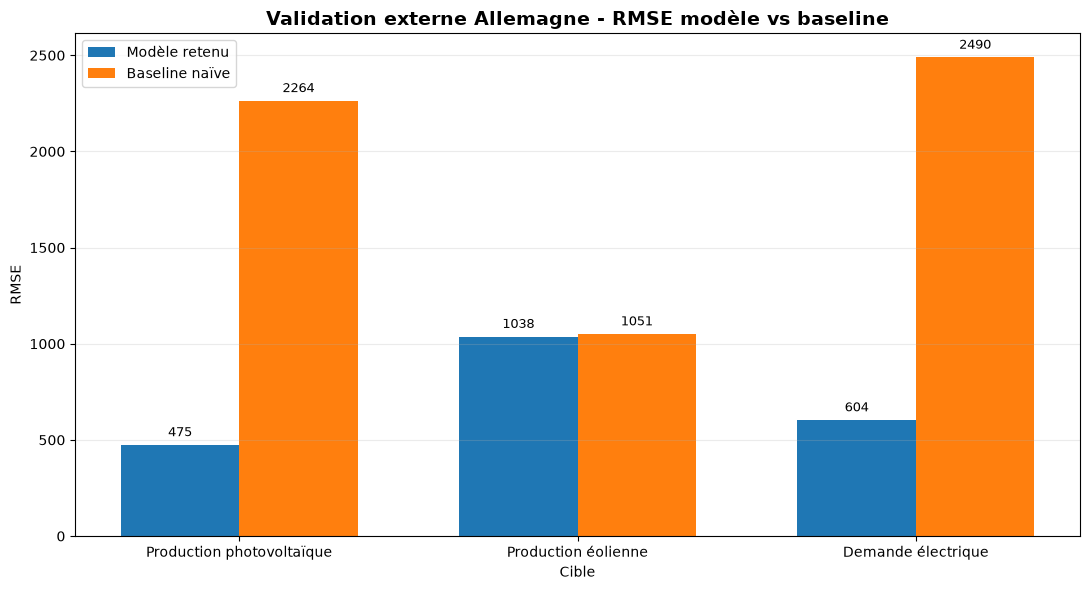

In [22]:
# RMSE : MODÈLE RETENU VS BASELINE

plot_df = final_test_results_df[
    [
        "Cible",
        "RMSE modèle",
        "RMSE baseline",
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_model = ax.bar(
    x - width / 2,
    plot_df["RMSE modèle"],
    width,
    label="Modèle retenu",
)

bars_baseline = ax.bar(
    x + width / 2,
    plot_df["RMSE baseline"],
    width,
    label="Baseline naïve",
)

ax.set_title(
    "Validation externe Allemagne - RMSE modèle vs baseline",
    fontsize=14,
    fontweight="bold",
)

ax.set_ylabel("RMSE")
ax.set_xlabel("Cible")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Cible"])

ax.legend()
ax.grid(axis="y", alpha=0.25)

# Valeurs au-dessus des barres
for bars in [bars_model, bars_baseline]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.0f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height,
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "external_validation_germany_rmse_vs_baseline.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figure sauvegardée :", figure_path)

plt.show()

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\external_validation_germany_pv_real_vs_pred.png


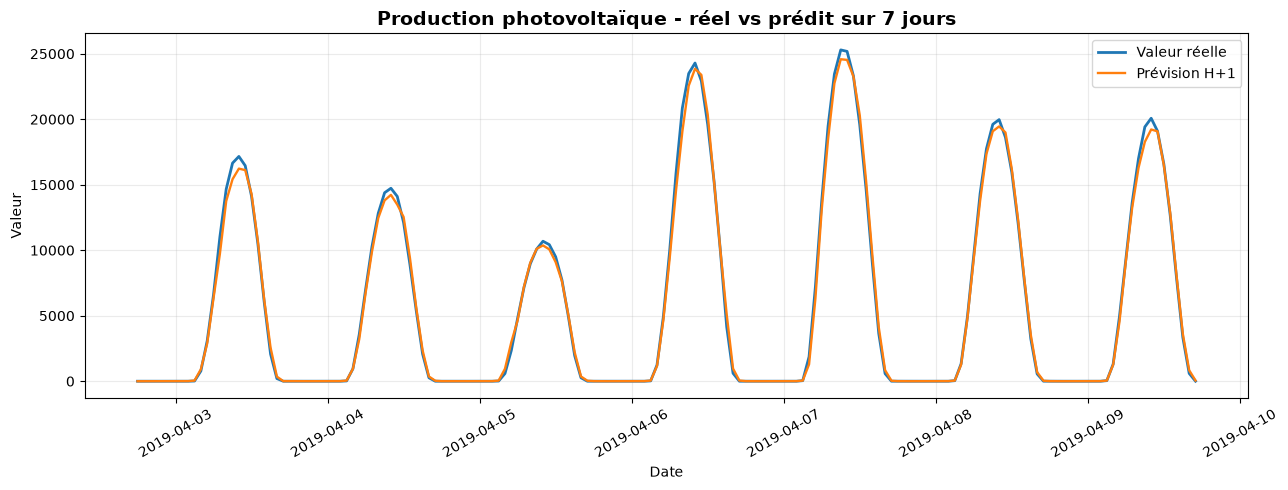

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\external_validation_germany_wind_real_vs_pred.png


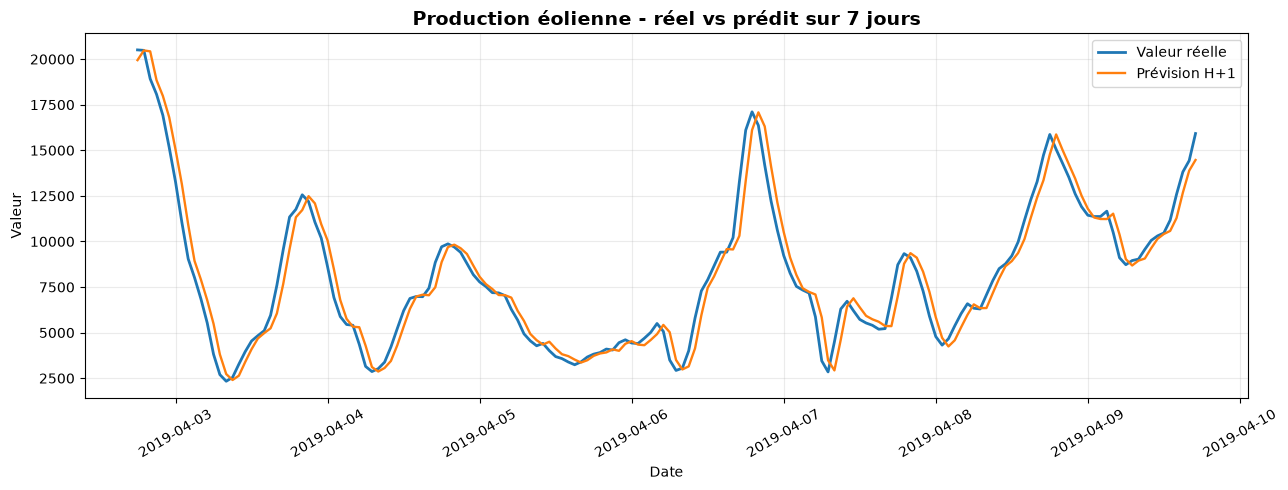

Figure sauvegardée : c:\Users\celes\Desktop\PFE\figures\external_validation_germany_demand_real_vs_pred.png


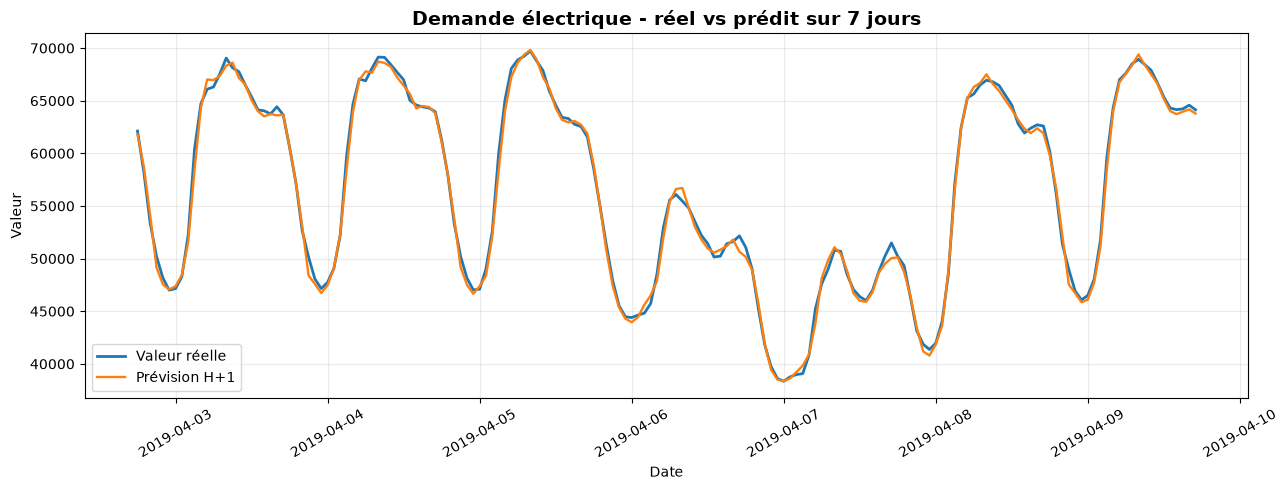

In [23]:
# RÉEL VS PRÉDIT / EXTRAIT DE 7 JOURS DU TEST

hours_to_display = 24 * 7

# Noms propres pour les fichiers
file_names = {
    "Production photovoltaïque": "pv",
    "Production éolienne": "wind",
    "Demande électrique": "demand",
}

for target_name in targets:

    predictions = (
        final_predictions[target_name]
        .iloc[:hours_to_display]
        .copy()
    )

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        predictions["utc_timestamp"],
        predictions["Réel"],
        label="Valeur réelle",
        linewidth=2,
    )

    ax.plot(
        predictions["utc_timestamp"],
        predictions["Prédit"],
        label="Prévision H+1",
        linewidth=1.7,
    )

    ax.set_title(
        f"{target_name} - réel vs prédit sur 7 jours",
        fontsize=14,
        fontweight="bold",
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Valeur")
    ax.legend()
    ax.grid(alpha=0.25)

    plt.xticks(rotation=30)
    plt.tight_layout()

    short_name = file_names[target_name]

    figure_path = (
        FIGURES_DIR
        / f"external_validation_germany_{short_name}_real_vs_pred.png"
    )

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    print("Figure sauvegardée :", figure_path)

    plt.show()

# Conclusion du Notebook 08

Cette expérimentation a permis d'évaluer la transférabilité de la méthodologie
de prévision H+1 sur un jeu de données énergétique externe indépendant relatif
au système électrique allemand.

Le protocole a conservé les principes méthodologiques du projet principal :

- respect strict de l'ordre chronologique ;
- construction explicite des cibles à H+1 ;
- séparation entraînement / validation / test ;
- sélection des modèles uniquement sur la validation ;
- utilisation unique du jeu de test externe ;
- comparaison systématique avec une baseline naïve.

Sur les 6 557 observations du jeu de test externe, HistGradientBoosting obtient
un gain de RMSE de 79,03 % pour la production photovoltaïque et de 75,74 %
pour la demande électrique par rapport à la baseline.

Pour la production éolienne, la régression linéaire conserve un coefficient
R² élevé, mais l'amélioration du RMSE par rapport à la baseline reste limitée
à 1,29 %. Ce résultat met en évidence l'importance de disposer de variables
explicatives directement liées au phénomène étudié, notamment de données de
vent pour la prévision éolienne.

Cette expérience ne démontre pas qu'un modèle entraîné sur le dataset principal
peut être appliqué directement à un autre pays. Les modèles ont été réentraînés
sur les données allemandes.

Elle montre en revanche que la méthodologie générale développée dans le projet
peut être reproduite sur un jeu de données énergétique externe indépendant,
avec des résultats particulièrement convaincants pour la production
photovoltaïque et la demande électrique.

La validation externe renforce ainsi la robustesse méthodologique du projet
tout en mettant en évidence ses limites et la dépendance des performances à la
qualité et à la nature des variables disponibles.